# Piloto GRPO: Qwen3-0.6B no GSM8K

Objetivo do piloto: provar que o pipeline inteiro funciona (avaliação antes, treino GRPO com LoRA, avaliação depois) antes de gastar GPU com o Qwen3-1.7B. Não é para tirar conclusão de acurácia ainda.

**Antes de rodar, no painel lateral do Kaggle (Session options):**
- Accelerator: **GPU T4 x2** (o notebook usa só uma)
- Internet: **On**
- Persistence: Files only (opcional, para não perder os arquivos se a sessão cair)

Depois é só *Run All*. Deve levar entre 30 e 90 minutos; cada etapa imprime quanto demorou. Os resultados ficam em `/kaggle/working/`.

Modo de pensar do Qwen3 **desligado** (`enable_thinking=False`): no PS4 cada token custa caro, então o alvo é acertar com respostas curtas.

In [4]:
# Instalação (Unsloth já traz versões compatíveis de TRL, transformers e peft)
!pip install -q unsloth

## Configuração

In [5]:
import os, re, json, time, random, math, dataclasses

SEED = 42
MODEL_NAME = "Qwen/Qwen3-0.6B"   # treino final: "Qwen/Qwen3-1.7B"
MAX_SEQ_LEN = 1024
MAX_PROMPT_LEN = 256
MAX_COMPLETION_LEN = 320
N_EVAL = 200          # subconjunto fixo do teste do GSM8K (mesma semente sempre)
EVAL_BATCH = 16
MAX_STEPS = 80
NUM_GENERATIONS = 8   # respostas amostradas por pergunta em cada passo do GRPO
LEARNING_RATE = 5e-6
LORA_R = 16
LENGTH_PENALTY = 0.0  # 0 = desligado. Ex.: 0.2 tira até 0,2 ponto das respostas corretas longas
OUT_DIR = "/kaggle/working"

random.seed(SEED)

In [6]:
# Versões e GPU (copie isto para o model card)
import unsloth  # precisa ser importado antes de trl/transformers
import torch, trl, transformers, peft, datasets
from unsloth import FastLanguageModel

print("GPU:", torch.cuda.get_device_name(0))
for m in (unsloth, trl, transformers, peft, datasets, torch):
    print(f"{m.__name__:>13}: {m.__version__}")

GPU: Tesla T4
      unsloth: 2026.10.11
          trl: 1.15.0
 transformers: 5.16.1
         peft: 0.20.0
     datasets: 4.8.5
        torch: 2.11.0+cu128


## Modelo com LoRA

In [7]:
t0 = time.time()
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name=MODEL_NAME,
    max_seq_length=MAX_SEQ_LEN,
    load_in_4bit=False,
    fast_inference=False,
)
model = FastLanguageModel.get_peft_model(
    model,
    r=LORA_R,
    lora_alpha=2 * LORA_R,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj",
                    "gate_proj", "up_proj", "down_proj"],
    use_gradient_checkpointing="unsloth",
    random_state=SEED,
)
print(f"Carregado em {time.time() - t0:.0f} s")

==((====))==  Unsloth 2026.10.11: Fast Qwen3 patching. Transformers: 5.16.1.
   \\   /|    Tesla T4. Num GPUs = 2. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:299: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:299: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


Unsloth: Not splitting across GPUs; the model fits on cuda:0 with room to train. Pass device_map = "unsloth_balanced" to split it anyway.


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Unsloth 2026.10.11 patched 28 layers with 28 QKV layers, 28 O layers and 28 MLP layers.


Unsloth: compiling each transformer block as one region (Qwen3DecoderLayer).
Carregado em 21 s


## Dados: GSM8K

In [8]:
from datasets import load_dataset

SYSTEM = ("Solve the math problem. Reason briefly, step by step. "
          "On the last line, write only the final answer as: #### <number>")

def build_prompt(question):
    msgs = [{"role": "system", "content": SYSTEM},
            {"role": "user", "content": question}]
    return tokenizer.apply_chat_template(
        msgs, tokenize=False, add_generation_prompt=True, enable_thinking=False)

def gold(answer_text):
    return answer_text.split("####")[-1].strip().replace(",", "")

ds = load_dataset("openai/gsm8k", "main")

train = ds["train"].shuffle(seed=SEED).map(
    lambda x: {"prompt": build_prompt(x["question"]), "answer": gold(x["answer"])})
train = train.remove_columns([c for c in train.column_names if c not in ("prompt", "answer")])
n_before = len(train)
train = train.filter(
    lambda x: len(tokenizer(x["prompt"], add_special_tokens=False).input_ids) <= MAX_PROMPT_LEN)
print(f"Treino: {len(train)} perguntas ({n_before - len(train)} removidas por prompt longo)")

test_sub = ds["test"].shuffle(seed=SEED).select(range(N_EVAL))
eval_rows = [{"question": q, "prompt": build_prompt(q), "answer": gold(a)}
             for q, a in zip(test_sub["question"], test_sub["answer"])]
print(f"Avaliação: {len(eval_rows)} perguntas do teste")
print("\n--- exemplo de prompt ---\n" + train[0]["prompt"])

README.md:   0%|          | 0.00/7.93k [00:00<?, ?B/s]

main/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.31MB            

main/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

main/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  419kB            

main/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/7473 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1319 [00:00<?, ? examples/s]

Map:   0%|          | 0/7473 [00:00<?, ? examples/s]

Filter:   0%|          | 0/7473 [00:00<?, ? examples/s]

Treino: 7472 perguntas (1 removidas por prompt longo)
Avaliação: 200 perguntas do teste

--- exemplo de prompt ---
<|im_start|>system
Solve the math problem. Reason briefly, step by step. On the last line, write only the final answer as: #### <number><|im_end|>
<|im_start|>user
Mimi picked up 2 dozen seashells on the beach.  Kyle found twice as many shells as Mimi and put them in his pocket. Leigh grabbed one-third of the shells that Kyle found.  How many seashells did Leigh have?<|im_end|>
<|im_start|>assistant
<think>

</think>




## Extração da resposta e recompensas

In [9]:
NUM = r"-?\d[\d,]*\.?\d*"

def to_float(s):
    if s is None:
        return None
    try:
        return float(str(s).replace(",", "").rstrip("."))
    except ValueError:
        return None

def extract_strict(text):
    m = re.findall(r"####\s*\$?\s*(" + NUM + ")", text)
    return to_float(m[-1]) if m else None

def extract_flex(text):
    v = extract_strict(text)
    if v is not None:
        return v
    m = re.findall(NUM, text)
    return to_float(m[-1]) if m else None

def same(a, b):
    return a is not None and b is not None and abs(a - b) < 1e-6

def text_of(c):
    return c if isinstance(c, str) else c[0]["content"]

def correctness_reward(prompts, completions, answer, **kwargs):
    return [2.0 if same(extract_flex(text_of(c)), to_float(a)) else 0.0
            for c, a in zip(completions, answer)]

def format_reward(completions, **kwargs):
    out = []
    for c in completions:
        lines = text_of(c).strip().splitlines()
        last = lines[-1].strip() if lines else ""
        ok = re.fullmatch(r"####\s*\$?\s*" + NUM + r"\s*\.?", last) is not None
        out.append(0.5 if ok else 0.0)
    return out

def length_reward(completions, answer, **kwargs):
    if LENGTH_PENALTY == 0:
        return [0.0] * len(completions)
    out = []
    for c, a in zip(completions, answer):
        t = text_of(c)
        n = len(tokenizer(t, add_special_tokens=False).input_ids)
        ok = same(extract_flex(t), to_float(a))
        out.append(-LENGTH_PENALTY * min(n, MAX_COMPLETION_LEN) / MAX_COMPLETION_LEN if ok else 0.0)
    return out

# Teste rápido das funções (precisa imprimir True em tudo)
_c = ["3 boxes * 12 = 36, 36 - 7 = 29\n#### 29",
      "The answer is 29.",
      "So she has $1,250.\n#### $1,250",
      "#### 30"]
_a = ["29", "29", "1250", "29"]
print(correctness_reward(None, _c, _a) == [2.0, 2.0, 2.0, 0.0])
print(format_reward(_c) == [0.5, 0.0, 0.5, 0.5])

True
True


## Avaliação (mesmo protocolo antes e depois)

In [10]:
import pandas as pd

def evaluate(rows, tag):
    FastLanguageModel.for_inference(model)
    old_side = tokenizer.padding_side
    tokenizer.padding_side = "left"
    recs, t0 = [], time.time()
    for i in range(0, len(rows), EVAL_BATCH):
        batch = rows[i:i + EVAL_BATCH]
        enc = tokenizer([r["prompt"] for r in batch], return_tensors="pt",
                        padding=True, add_special_tokens=False).to("cuda")
        with torch.no_grad():
            out = model.generate(**enc, max_new_tokens=MAX_COMPLETION_LEN,
                                 do_sample=False, pad_token_id=tokenizer.pad_token_id)
        gen = out[:, enc["input_ids"].shape[1]:]
        for r, g in zip(batch, gen):
            ids = [t for t in g.tolist() if t != tokenizer.pad_token_id]
            text = tokenizer.decode(ids, skip_special_tokens=True)
            gold_v = to_float(r["answer"])
            recs.append({
                "question": r["question"], "gold": r["answer"], "output": text,
                "n_tokens": len(ids),
                "truncated": len(ids) >= MAX_COMPLETION_LEN,
                "correct_strict": same(extract_strict(text), gold_v),
                "correct_flex": same(extract_flex(text), gold_v),
            })
    tokenizer.padding_side = old_side
    FastLanguageModel.for_training(model)
    df = pd.DataFrame(recs)
    df.to_csv(f"{OUT_DIR}/eval_{tag}.csv", index=False)
    summary = {
        "tag": tag, "n": len(df),
        "acc_strict": round(df.correct_strict.mean(), 4),
        "acc_flex": round(df.correct_flex.mean(), 4),
        "mean_tokens": round(df.n_tokens.mean(), 1),
        "truncated_rate": round(df.truncated.mean(), 4),
        "seconds": round(time.time() - t0),
    }
    print(summary)
    return summary

base = evaluate(eval_rows, "base")

Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

{'tag': 'base', 'n': 200, 'acc_strict': np.float64(0.015), 'acc_flex': np.float64(0.545), 'mean_tokens': np.float64(142.2), 'truncated_rate': np.float64(0.025), 'seconds': 247}


## Treino GRPO

In [11]:
from trl import GRPOConfig, GRPOTrainer

major, _ = torch.cuda.get_device_capability()
cfg = dict(
    output_dir=f"{OUT_DIR}/grpo_pilot",
    learning_rate=LEARNING_RATE,
    lr_scheduler_type="cosine",
    warmup_ratio=0.05,
    per_device_train_batch_size=NUM_GENERATIONS,  # 1 pergunta x NUM_GENERATIONS respostas por passo
    gradient_accumulation_steps=1,
    num_generations=NUM_GENERATIONS,
    max_prompt_length=MAX_PROMPT_LEN,
    max_completion_length=MAX_COMPLETION_LEN,
    max_steps=MAX_STEPS,
    logging_steps=1,
    save_steps=40,
    report_to="none",
    seed=SEED,
    bf16=major >= 8,
    fp16=major < 8,   # T4 não tem bf16
    optim="adamw_torch",
    max_grad_norm=0.1,
)
# Descarta opções que a versão instalada do TRL não conhece, em vez de quebrar
known = {f.name for f in dataclasses.fields(GRPOConfig)}
dropped = [k for k in cfg if k not in known]
if dropped:
    print("Ignorado nesta versão do TRL:", dropped)
args = GRPOConfig(**{k: v for k, v in cfg.items() if k in known})

trainer = GRPOTrainer(
    model=model,
    processing_class=tokenizer,
    reward_funcs=[correctness_reward, format_reward, length_reward],
    args=args,
    train_dataset=train,
)
t0 = time.time()
trainer.train()
train_minutes = (time.time() - t0) / 60
print(f"Treino: {train_minutes:.1f} min")

Ignorado nesta versão do TRL: ['warmup_ratio', 'max_prompt_length']
Unsloth: GRPO now defaults to TRL's loss_type = 'dapo' with beta = 0.0. Set loss_type = 'bnpo', beta = 0.001 for Unsloth's previous default.


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 7,472 | Num Epochs = 1 | Total steps = 80
O^O/ \_/ \    Batch size per device = 8 | Gradient accumulation steps = 1
\        /    Data Parallel GPUs = 1 | Total batch size (8 x 1 x 1) = 8
 "-____-"     Trainable parameters = 10,092,544 of 606,142,464 (1.67% trained)
Passing `generation_config` together with generation-related arguments=({'cache_implementation', 'pad_token_id'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. P

Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: GRPO PrefixGrouper is off: its flex attention kernel does not compile with torch 2.11.0+cu128 on this GPU (RuntimeError: No valid triton configs. OutOfMemoryError: out of resource: triton_tem_fused_flex_attention_0 Required: 98304 Hardware limit:65536 Reducing block sizes or `num_stages` may help.); using the packed path.


Step,Training Loss,reward,reward_std,completions / mean_length,completions / min_length,completions / max_length,completions / clipped_ratio,completions / mean_terminated_length,completions / min_terminated_length,completions / max_terminated_length,kl,rewards / correctness_reward / mean,rewards / correctness_reward / std,rewards / format_reward / mean,rewards / format_reward / std,rewards / length_reward / mean,rewards / length_reward / std
1,0.000000,0.000000,0.000000,161.125000,109.000000,204.000000,0.000000,161.125000,109.000000,204.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,0.152466,0.500000,0.925820,132.375000,65.000000,250.000000,0.000000,132.375000,65.000000,250.000000,0.000000,0.500000,0.925820,0.000000,0.000000,0.000000,0.000000
3,-0.100061,0.750000,1.035098,160.500000,117.000000,225.000000,0.000000,160.500000,117.000000,225.000000,0.000000,0.750000,1.035098,0.000000,0.000000,0.000000,0.000000
4,-0.136983,0.250000,0.707107,160.000000,56.000000,277.000000,0.000000,160.000000,56.000000,277.000000,0.000000,0.250000,0.707107,0.000000,0.000000,0.000000,0.000000
5,0.155765,0.062500,0.176777,134.125000,75.000000,184.000000,0.000000,134.125000,75.000000,184.000000,0.000000,0.000000,0.000000,0.062500,0.176777,0.000000,0.000000
6,0.034359,1.500000,0.925820,131.625000,96.000000,184.000000,0.000000,131.625000,96.000000,184.000000,0.000000,1.500000,0.925820,0.000000,0.000000,0.000000,0.000000
7,-0.141402,2.125000,0.231455,86.375000,62.000000,129.000000,0.000000,86.375000,62.000000,129.000000,0.000000,2.000000,0.000000,0.125000,0.231455,0.000000,0.000000
8,-0.137498,0.375000,0.694365,146.125000,94.000000,206.000000,0.000000,146.125000,94.000000,206.000000,0.000000,0.250000,0.707107,0.125000,0.231455,0.000000,0.000000
9,0.075678,2.062500,0.176777,77.625000,61.000000,98.000000,0.000000,77.625000,61.000000,98.000000,0.000000,2.000000,0.000000,0.062500,0.176777,0.000000,0.000000
10,-0.194621,0.500000,0.925820,123.125000,90.000000,170.000000,0.000000,123.125000,90.000000,170.000000,0.000000,0.500000,0.925820,0.000000,0.000000,0.000000,0.000000


Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

Treino: 15.1 min


## Avaliação depois do treino

In [12]:
after = evaluate(eval_rows, "grpo_pilot")
comp = pd.DataFrame([base, after]).set_index("tag")
comp.to_csv(f"{OUT_DIR}/comparacao.csv")
comp

Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

{'tag': 'grpo_pilot', 'n': 200, 'acc_strict': np.float64(0.12), 'acc_flex': np.float64(0.575), 'mean_tokens': np.float64(137.0), 'truncated_rate': np.float64(0.03), 'seconds': 247}


,n,acc_strict,acc_flex,mean_tokens,truncated_rate,seconds
tag,,,,,,
base,200,0.015,0.545,142.2,0.025,247
grpo_pilot,200,0.120,0.575,137.0,0.030,247


## Curvas do treino

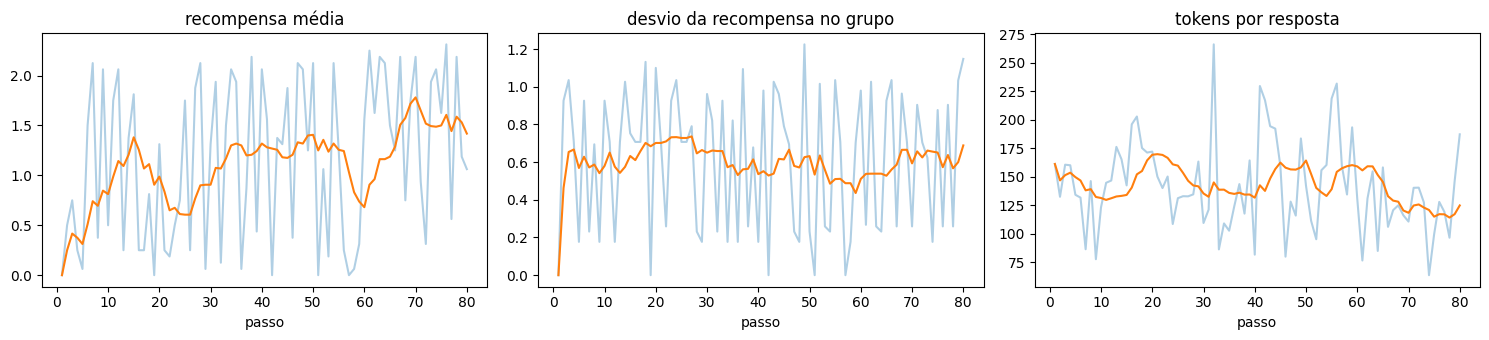

In [13]:
import matplotlib.pyplot as plt

log = pd.DataFrame([h for h in trainer.state.log_history if "reward" in h])
log.to_csv(f"{OUT_DIR}/log_treino.csv", index=False)

len_col = next((c for c in ("completions/mean_length", "completion_length") if c in log.columns), None)
panels = [("reward", "recompensa média"), ("reward_std", "desvio da recompensa no grupo")]
if len_col:
    panels.append((len_col, "tokens por resposta"))

fig, axes = plt.subplots(1, len(panels), figsize=(5 * len(panels), 3.5))
for ax, (col, title) in zip(axes, panels):
    ax.plot(log["step"], log[col], alpha=0.35)
    ax.plot(log["step"], log[col].rolling(10, min_periods=1).mean())
    ax.set_title(title); ax.set_xlabel("passo")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/curvas_treino.png", dpi=120)
plt.show()

In [14]:
# Salva só o adaptador LoRA (nada é enviado ao Hugging Face no piloto)
model.save_pretrained(f"{OUT_DIR}/lora_pilot")
tokenizer.save_pretrained(f"{OUT_DIR}/lora_pilot")
print(json.dumps({"base": base, "grpo_pilot": after,
                  "train_minutes": round(train_minutes, 1)}, indent=2))

Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/lora_pilot/tokenizer_config.json.


{
  "base": {
    "tag": "base",
    "n": 200,
    "acc_strict": 0.015,
    "acc_flex": 0.545,
    "mean_tokens": 142.2,
    "truncated_rate": 0.025,
    "seconds": 247
  },
  "grpo_pilot": {
    "tag": "grpo_pilot",
    "n": 200,
    "acc_strict": 0.12,
    "acc_flex": 0.575,
    "mean_tokens": 137.0,
    "truncated_rate": 0.03,
    "seconds": 247
  },
  "train_minutes": 15.1
}


## Como ler o resultado

O piloto deu certo se:
1. **A recompensa média sobe** ao longo dos passos (a linha suavizada no gráfico).
2. **O desvio da recompensa não fica em zero.** Se ficar, todas as 8 respostas de cada pergunta tiraram a mesma nota e o GRPO não tem o que aprender.
3. **O formato melhora:** `acc_strict` (resposta com `####`) deve se aproximar de `acc_flex`.

Com 80 passos no 0.6B, a acurácia pode subir pouco ou nada, e tudo bem. O piloto serve para validar o pipeline e medir tempo por passo; a decisão sobre o GRPO é no treino do 1.7B.

**Me mande:** a saída da célula de versões, a tabela de comparação, a imagem das curvas e o tempo de treino.